# Chain-of-Thought Baseline on GSM8K

This notebook does two things:

1. Ask Llama-3.2-3B to solve GSM8K math problems step by step, and measure accuracy.
2. Take the problems it got wrong and **sort them into error types**, then plot the result.

The second part is the important one. A later experiment asks whether a certain metric can
spot bad reasoning steps. To interpret that result, you first need to know **what kinds of
mistakes actually happen here**.

Just run the cells from top to bottom.

## 1. Install and import

In [1]:
!pip install -q transformers datasets accelerate matplotlib pandas

In [2]:
import re
import json

import torch
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm.auto import tqdm
from dotenv import load_dotenv
from huggingface_hub import login

print("torch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.12.0+cu126
GPU available: True


In [3]:
load_dotenv("secret.env")
login()

## 2. Load GSM8K

GSM8K is a dataset of grade-school word problems. Each item has a `question` and an
`answer` (a worked solution written by a human).

In [4]:
gsm8k = load_dataset("openai/gsm8k", "main")

print("Test set size:", len(gsm8k["test"]))
print()
print("=== Example question ===")
print(gsm8k["test"][0]["question"])
print()
print("=== Example reference solution ===")
print(gsm8k["test"][0]["answer"])

Test set size: 1319

=== Example question ===
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

=== Example reference solution ===
Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18


In the reference solution, `<<48/2=24>>` is a calculator annotation that ships with the
dataset — you can ignore it. The last line, `#### 72`, is the gold answer.

## 3. Load the model

In [5]:
MODEL_ID = "meta-llama/Meta-Llama-3-8B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Some models have no pad token; reusing the end-of-text token is fine here.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,   # half precision, saves GPU memory
    device_map="auto",            # put it on the GPU automatically
)
model.eval()                      # inference only, no training

print("Model loaded on:", model.device)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Model loaded on: cuda:0


## 4. Helper functions

### A note on `extract_answer`

We ask the model to finish with `The final answer is #### 72`, then pull the number out.

**There is a trap here.** A common shortcut is: "if you can't find `####`, just take the last
number anywhere in the text." That inflates accuracy — when the model goes completely off the
rails and never states an answer, the last number in its text might happen to equal the gold
answer, and it gets scored as correct.

So instead: if we can't find a properly formatted answer, return `None` and record the item as
a **formatting failure**. It counts as neither right nor wrong.

In [6]:
def extract_answer(text):
    """Find '#### <number>' in the text and return it as a float. Return None if absent."""
    if "####" not in text:
        return None
    tail = text.split("####")[-1]                 # everything after ####
    m = re.search(r"-?\d[\d,]*\.?\d*", tail)      # first number in there
    if m is None:
        return None
    num = m.group(0).replace(",", "")             # "1,200" -> "1200"
    try:
        return float(num)
    except ValueError:
        return None


SYSTEM_PROMPT = (
    "You are a precise mathematical assistant. "
    "Solve the following word problem step-by-step. "
    "Provide clear reasoning, and end your response by stating the final answer "
    "in the format: The final answer is #### [number]."
    "Make sure the response ends in this EXACT format - 4 hashtag symbols "
    "followed by a number. Answers not following this format will fail "
    "parsing and be marked as false."
)


def build_prompt(question):
    """Wrap the question in Llama's chat template."""
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )


# Quick sanity check
print(extract_answer("blah The final answer is #### 1,200."))   # 1200.0
print(extract_answer("I forgot to give an answer"))             # None

1200.0
None


## 5. Run the evaluation

Set `N_SAMPLES` small (say 20) first to check everything works, then raise it to 200 for the
real run.

`do_sample=False` means **greedy decoding**: always pick the highest-probability next word.
That makes the output identical every time you run it, so your experiment is reproducible.

In [7]:
N_SAMPLES = 200          # start with 20 for a test run
MAX_NEW_TOKENS = 512     # generation length cap

test_samples = gsm8k["test"].select(range(N_SAMPLES))
results = []

for sample in tqdm(test_samples):
    question = sample["question"]
    gold_text = sample["answer"]

    prompt = build_prompt(question)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False)
    inputs = inputs.to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,                  # greedy: reproducible
            pad_token_id=tokenizer.pad_token_id,
        )

    # generate() returns prompt + continuation, so cut the prompt off
    new_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    trace = tokenizer.decode(new_ids, skip_special_tokens=True)

    results.append({
        "question": question,
        "gold_solution": gold_text,
        "trace": trace,                       # the model's full reasoning
        "gold": extract_answer(gold_text),
        "pred": extract_answer(trace),
    })

print("Done -", len(results), "problems")

  0%|          | 0/200 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=512) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `

Done - 200 problems


In [8]:
# Score everything
n_total = len(results)
n_parsed = 0     # how many produced a readable answer
n_correct = 0

for r in results:
    if r["pred"] is None:
        r["status"] = "no_answer"        # never stated an answer in the right format
    elif abs(r["pred"] - r["gold"]) < 1e-6:
        r["status"] = "correct"
        n_correct += 1
        n_parsed += 1
    else:
        r["status"] = "wrong"
        n_parsed += 1

print(f"Total problems      : {n_total}")
print(f"Gave an answer      : {n_parsed}")
print(f"Gave no answer      : {n_total - n_parsed}")
print(f"Correct             : {n_correct}")
print()
print(f"Accuracy (all items)     : {n_correct / n_total * 100:.1f}%")
print(f"Accuracy (answered only) : {n_correct / max(n_parsed, 1) * 100:.1f}%")

# Save for the next notebook
with open("baseline_results.json", "w") as f:
    json.dump(results, f, ensure_ascii=False, indent=1)
print("\nSaved to baseline_results.json")

Total problems      : 200
Gave an answer      : 194
Gave no answer      : 6
Correct             : 161

Accuracy (all items)     : 80.5%
Accuracy (answered only) : 83.0%

Saved to baseline_results.json


## 6. Automatically find arithmetic slips

Before doing anything by hand, let the code find some of the mistakes for you.

The idea is simple. The model writes expressions like `12 + 3 = 15` in its reasoning. Find them
with a regular expression, **compute them yourself**, and check whether the number after the
equals sign is right.

Two limitations worth understanding:

- It only sees mistakes written out as an explicit expression. If the model just says
  "so there are 15 in total", this finds nothing.
- It checks whether a calculation **was done correctly**, not whether it **should have been done
  at all**. The model can have every arithmetic step right and still have misread the question.

So this gives you *hints* for the manual step below. It does not replace it.

In [9]:
# Matches things like "12 + 3 = 15"
CALC_PATTERN = re.compile(
    r"(\d[\d,]*\.?\d*)\s*([+\-*/x×÷])\s*(\d[\d,]*\.?\d*)\s*=\s*(\d[\d,]*\.?\d*)"
)

def to_float(s):
    return float(s.replace(",", ""))

def check_arithmetic(text):
    """Return a list of expressions in `text` whose result is wrong."""
    bad = []
    for m in CALC_PATTERN.finditer(text):
        a_s, op, b_s, c_s = m.groups()
        try:
            a, b, c = to_float(a_s), to_float(b_s), to_float(c_s)
        except ValueError:
            continue

        if op == "+":
            real = a + b
        elif op == "-":
            real = a - b
        elif op in "*x×":
            real = a * b
        elif op in "/÷":
            if b == 0:
                continue
            real = a / b
        else:
            continue

        # Allow floating-point noise, and allow the model to have rounded
        if abs(real - c) > 1e-4 and abs(round(real) - c) > 1e-4:
            bad.append({"expr": m.group(0), "should_be": real})
    return bad


for r in results:
    r["bad_calcs"] = check_arithmetic(r["trace"])

wrong = [r for r in results if r["status"] == "wrong"]
n_with_bad = sum(1 for r in wrong if r["bad_calcs"])

print(f"Wrong answers: {len(wrong)}")
print(f"Of those, containing a detectable arithmetic slip: "
      f"{n_with_bad} ({n_with_bad / max(len(wrong), 1) * 100:.0f}%)")
print()
print("=== Example ===")
for r in wrong:
    if r["bad_calcs"]:
        print("Question:", r["question"][:100])
        for b in r["bad_calcs"][:3]:
            print(f'  wrote "{b["expr"]}", should be {b["should_be"]}')
        break

Wrong answers: 33
Of those, containing a detectable arithmetic slip: 4 (12%)

=== Example ===
Question: John has 3 boxes.  Each box is 5 inches by 6 inches by 4 inches.  The walls are 1 inch thick.  What 
  wrote "6 × 4 = 120", should be 24.0


## 7. Manual labelling: what kind of mistake was it?

The automatic check only covers part of the picture. The rest needs your eyes.

This cell writes a file called `errors_to_label.csv`. **Open it in Excel**, fill in the
`error_type` column, save it as CSV, then run the plotting cell below.

Use these five labels. Don't invent more — with a small sample, extra categories just leave you
with two or three items in each bucket, which tells you nothing.

| label | meaning | example |
|---|---|---|
| `arith` | right approach, wrong calculation | wrote `6 × 7 = 41` |
| `missing_step` | skipped part of the problem | forgot to add the tax |
| `misread` | misunderstood the question | read "per person" as "in total" |
| `off_topic` | drifted away, answered something else | started solving a different problem |
| `other` | none of the above | |

**Practical advice:** label 50 items, not 200. Fifty is plenty for a distribution plot, and
labelling for hours tends to make your own standards drift partway through.

When labelling, read the question and the model's reasoning **before** looking at the reference
solution — otherwise it is hard not to see what you expect to see.

In [10]:
N_TO_LABEL = 50   # label the first 50 wrong answers

to_label = wrong[:N_TO_LABEL]

rows = []
for i, r in enumerate(to_label):
    rows.append({
        "id": i,
        "error_type": "",                             # <-- the column you fill in
        "auto_bad_calc": len(r["bad_calcs"]) > 0,     # hint from the automatic check
        "gold": r["gold"],
        "pred": r["pred"],
        "question": r["question"],
        "model_trace": r["trace"],
        "gold_solution": r["gold_solution"],
    })

pd.DataFrame(rows).to_csv("errors_to_label.csv", index=False)

print(f"Wrote errors_to_label.csv with {len(rows)} rows")
print("Open it in Excel, fill in the error_type column, save, then run the plotting cell.")

Wrote errors_to_label.csv with 33 rows
Open it in Excel, fill in the error_type column, save, then run the plotting cell.


### Prefer to read them inside the notebook? Use this.

In [11]:
def show_case(i):
    """Print wrong answer number i so you can judge it."""
    r = to_label[i]
    print("=" * 70)
    print(f"[item {i}]  gold = {r['gold']}   model = {r['pred']}")
    print("=" * 70)
    print("--- QUESTION ---")
    print(r["question"])
    print("\n--- MODEL REASONING ---")
    print(r["trace"])
    if r["bad_calcs"]:
        print("\n--- ARITHMETIC SLIPS FOUND AUTOMATICALLY ---")
        for b in r["bad_calcs"]:
            print(f'   "{b["expr"]}"  should be {b["should_be"]}')
    print("\n--- REFERENCE SOLUTION ---")
    print(r["gold_solution"])


show_case(0)   # change the number to see other items

[item 0]  gold = 160.0   model = 180.0
--- QUESTION ---
Carla is downloading a 200 GB file. Normally she can download 2 GB/minute, but 40% of the way through the download, Windows forces a restart to install updates, which takes 20 minutes. Then Carla has to restart the download from the beginning. How load does it take to download the file?

--- MODEL REASONING ---
Let's break down the problem step-by-step:

1. Carla is downloading a 200 GB file. To find the total time it would take to download the file normally, we can divide the file size by the download rate:

200 GB / 2 GB/minute = 100 minutes

So, it would take Carla 100 minutes to download the file normally.

2. However, Windows forces a restart to install updates 40% of the way through the download. To find the percentage of the file downloaded at this point, we can multiply the total file size by the percentage:

200 GB x 0.40 = 80 GB

So, Carla has downloaded 80 GB of the file when the restart occurs.

3. The restart takes 20

## 8. Plot the distribution

Labelled: 0
Series([], Name: count, dtype: int64)


ValueError: All wedge sizes are zero

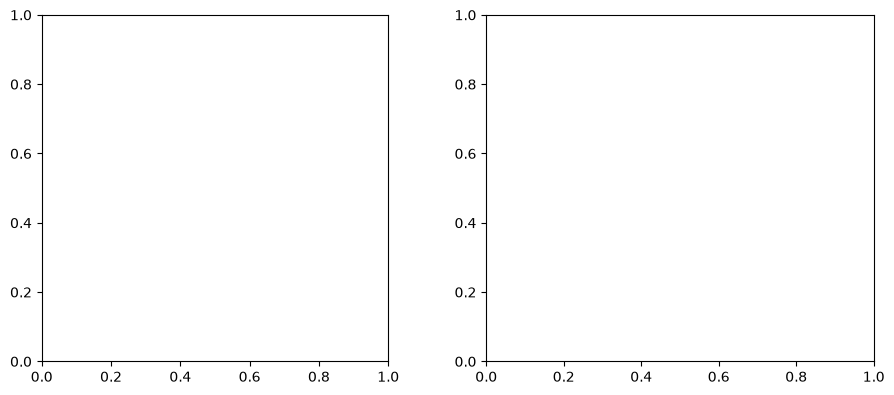

In [12]:
df = pd.read_csv("errors_to_label.csv")

# Drop rows you haven't labelled yet
df = df[df["error_type"].notna() & (df["error_type"].astype(str).str.strip() != "")]
df["error_type"] = df["error_type"].astype(str).str.strip()

print("Labelled:", len(df))
print(df["error_type"].value_counts())

counts = df["error_type"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].pie(counts.values, labels=counts.index, autopct="%1.0f%%", startangle=90)
axes[0].set_title(f"Error types (n={len(df)})")

axes[1].bar(counts.index, counts.values)      # easier to read exact counts
axes[1].set_ylabel("count")
axes[1].set_title("Error types (count)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("error_types.png", dpi=150)       # ready to drop into the thesis
plt.show()

In [ ]:
# Cross-check: does the automatic detector agree with your labels?
# If most items you labelled `arith` were also flagged automatically, the detector is trustworthy.
# If they disagree a lot, either the regex or the labelling standard needs another look.
print("rows = your label, columns = automatic check found a bad expression")
print(pd.crosstab(df["error_type"], df["auto_bad_calc"]))

rows = your label, columns = automatic check found a bad expression
auto_bad_calc  False  True 
error_type                 
arith              0      1
misread            2      0
off_topic          3      0
other              2      0


## 9. What you now have

Three things, all of which the thesis needs:

1. **A baseline accuracy number.** Every later experiment gets compared against it.
2. **`baseline_results.json`** — every reasoning trace, so the next notebook can load them
   instead of re-running the model.
3. **`error_types.png`** — the distribution of failure modes.

The third one matters most, because it sets up how the next experiment gets read.

If `arith` turns out to be the largest slice, that means **the dominant failure mode on GSM8K is
arithmetic slips**. And arithmetic slips have an awkward property: to a language model,
`6 × 7 = 41` and `6 × 7 = 42` look almost equally natural, so any probability-based metric will
struggle to tell them apart.

So if the later experiment finds that the metric cannot detect arithmetic errors, **that is not a
failed experiment — it is the outcome this plot predicted.** Those two chapters are linked, and
the thesis should say so explicitly.

### Optional extras, if there is time

- Run a different model size (1B or 8B) and see whether the error distribution changes.
- Check whether accuracy drops as the number of reasoning steps grows.
- Set `do_sample=True`, run the same problem 5 times, and see how stable the answer is.